# 03 — Model Training

Two-phase EfficientNet-B4 training with:
- Patient-level stratified splitting (no data leakage)
- **Professional class balancing**: weighted sampler + class-weighted loss
- Phase 1: head-only training
- Phase 2: fine-tuning with cosine warmup
- Mixed-precision (AMP) for speed
- Checkpointing on Quadratic Weighted Kappa

In [2]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
from src.data_manager import ensure_dataset

ensure_dataset()
config.ensure_dirs()

print(f"Images dir: {config.IMAGES_DIR} (exists: {os.path.isdir(config.IMAGES_DIR)})")
print(f"Outputs dir: {config.OUTPUTS_DIR}")

/home/dhiashalabi/development/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Images dir: /home/dhiashalabi/development/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped (exists: True)
Outputs dir: /home/dhiashalabi/development/diabetic_retinopathy/outputs


In [3]:
import pandas as pd

from src import config
from src.augmentations import get_train_transforms, get_valid_transforms
from src.dataset import (
    compute_class_weights,
    create_dataloaders,
    load_and_split_dataframe,
    preprocess_images_to_cache,
)
from src.model import build_model, count_parameters
from src.trainer import Trainer
from src.utils import get_device, seed_everything

seed_everything()
device = get_device()

Using GPU: NVIDIA GeForce GTX 1050 (4.3 GB)


/home/dhiashalabi/development/diabetic_retinopathy/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:371: UserWarning: Found GPU0 NVIDIA GeForce GTX 1050 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Please follow the instructions at https://pytorch.org/get-started/locally/ to install a PyTorch release that supports one of these CUDA versions: 12.6
  _warn_unsupported_code(d, device_cc, code_ccs)
/home/dhiashalabi/development/diabetic_retinopathy/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:489: UserWarning: 
NVIDIA GeForce GTX 1050 with CUDA capability sm_61 is

## 1. Data Preparation with Balanced Splitting

In [4]:
# Patient-level stratified split — both eyes of each patient stay together
train_df, valid_df, test_df = load_and_split_dataframe()

print(f'Train : {len(train_df):,} images  ({train_df["patient_id"].nunique():,} patients)')
print(f'Valid : {len(valid_df):,} images  ({valid_df["patient_id"].nunique():,} patients)')
print(f'Test  : {len(test_df):,} images  ({test_df["patient_id"].nunique():,} patients)')
print('\nTrain class distribution:')
print(train_df['level'].value_counts().sort_index())

Train : 24,573 images  (12,292 patients)
Valid : 5,267 images  (2,634 patients)
Test  : 5,268 images  (2,635 patients)

Train class distribution:
level
0    18086
1     1689
2     3683
3      613
4      502
Name: count, dtype: int64


In [5]:
# Compute class weights for the loss function
class_weights = compute_class_weights(train_df['level'].values)
print('Class weights (balanced):')
for i, (name, w) in enumerate(zip(config.CLASS_NAMES, class_weights, strict=False)):
    print(f'  {name:20s}: {w:.4f}')

Class weights (balanced):
  No_DR               : 0.2717
  Mild                : 2.9098
  Moderate            : 1.3344
  Severe              : 8.0173
  Proliferative_DR    : 9.7900


In [ ]:
# Build DataLoaders with WeightedRandomSampler for balanced mini-batches
train_transforms = get_train_transforms()
valid_transforms = get_valid_transforms()

# One-time preprocessing cache to remove heavy CPU work from __getitem__
all_splits_df = pd.concat(
    [
        train_df[["image", "level"]],
        valid_df[["image", "level"]],
        test_df[["image", "level"]],
    ],
    ignore_index=True,
).drop_duplicates(subset=["image"])

cached_images_dir = preprocess_images_to_cache(
    df=all_splits_df,
    source_images_dir=config.IMAGES_DIR,
    img_size=config.IMG_SIZE,
)

loaders = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    test_df=test_df,
    train_transform=train_transforms,
    valid_transform=valid_transforms,
    images_dir=cached_images_dir,
    batch_size=config.PHASE1_BATCH_SIZE,
    preprocessing=False,
    use_sampler=True,  # WeightedRandomSampler for class balancing
)

print(f'\nUsing preprocessed cache dir: {cached_images_dir}')
print(f'Train batches per epoch: {len(loaders["train"])}')
print(f'Valid batches          : {len(loaders["valid"])}')
print(f'Test  batches          : {len(loaders["test"])}')

## 2. Verify Balanced Sampling

The WeightedRandomSampler should produce roughly uniform class distribution in each batch, despite the 73%/5%/15%/2%/5% natural imbalance.

In [7]:
# Verify that the sampler produces balanced batches
from collections import Counter

batch_labels = []
for i, (imgs, labels) in enumerate(loaders['train']):
    batch_labels.extend(labels.numpy().tolist())
    if i >= 19:  # check first 20 batches
        break

counter = Counter(batch_labels)
total = sum(counter.values())
print('Class distribution in first 20 training batches (with balanced sampler):')
for cls in sorted(counter.keys()):
    print(f'  Class {cls} ({config.CLASS_NAMES[cls]:20s}): {counter[cls]:4d} ({100*counter[cls]/total:.1f}%)')
print(f'  Total samples: {total}')

Class distribution in first 20 training batches (with balanced sampler):
  Class 0 (No_DR               ):  239 (18.7%)
  Class 1 (Mild                ):  294 (23.0%)
  Class 2 (Moderate            ):  232 (18.1%)
  Class 3 (Severe              ):  244 (19.1%)
  Class 4 (Proliferative_DR    ):  271 (21.2%)
  Total samples: 1280


## 3. Build Model

In [8]:
model = build_model(pretrained=True)
params = count_parameters(model)
print(f'Model: {config.MODEL_NAME}')
print(f'Total parameters : {params["total"]:,}')
print(f'Trainable        : {params["trainable"]:,} ({params["trainable_pct"]:.1f}%)')
print(f'Input size       : {config.IMG_SIZE}x{config.IMG_SIZE}')
print(f'Num classes      : {config.NUM_CLASSES}')

Model: efficientnet_b4
Total parameters : 18,473,805
Trainable        : 18,473,805 (100.0%)
Input size       : 380x380
Num classes      : 5


## 4. Train

Set `RESUME = True` to automatically continue from where training left off if
Colab disconnects or the runtime crashes.  Set to `False` to start fresh.

In [9]:
RESUME = True   # flip to False to discard any saved state and train from scratch

trainer = Trainer(
    model=model,
    device=device,
    class_weights=class_weights,
)

if RESUME and Trainer.has_resume_state():
    print(f'Resume state found at {config.RESUME_STATE_PATH}')
else:
    print('Starting fresh training run.')

history = trainer.fit(
    train_loader=loaders['train'],
    valid_loader=loaders['valid'],
    resume=RESUME,
)

2026-03-26 10:56:23 | src.trainer | INFO | Phase 1 params: 925,189 trainable / 18,473,805 total (5.0%)
2026-03-26 10:56:23 | src.trainer | INFO | 
2026-03-26 10:56:23 | src.trainer | INFO | Phase: PHASE1 | Epochs: 10 | LR: 0.004
2026-03-26 10:56:23 | src.trainer | INFO | ============================================================


Starting fresh training run.


  Train:   0%|          | 0/383 [00:00<?, ?it/s]

2026-03-26 10:56:56 | src.trainer | INFO | Epoch 01/10 (33s) | LR: 4.00e-03 | Train Loss: 6.3096 Acc: 0.3342 QWK: 0.3088 | Val Loss: 4.2411 Acc: 0.0666 QWK: 0.0831
2026-03-26 10:56:56 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase1.pth (QWK=0.0831)
2026-03-26 10:57:28 | src.trainer | INFO | Epoch 02/10 (31s) | LR: 3.90e-03 | Train Loss: 1.8698 Acc: 0.3577 QWK: 0.3416 | Val Loss: 2.7990 Acc: 0.0644 QWK: 0.0800
2026-03-26 10:57:57 | src.trainer | INFO | Epoch 03/10 (30s) | LR: 3.62e-03 | Train Loss: 1.2239 Acc: 0.3757 QWK: 0.3721 | Val Loss: 2.5631 Acc: 0.0642 QWK: 0.1121
2026-03-26 10:57:58 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase1.pth (QWK=0.1121)
2026-03-26 10:58:29 | src.trainer | INFO | Epoch 04/10 (31s) | LR: 3.18e-03 | Train Loss: 1.0334 Acc: 0.3943 QWK: 0.4149 | Val Loss: 2.4649 Acc: 0.0735 QWK: 0.1295
2026-03-

## 5. Training Curves

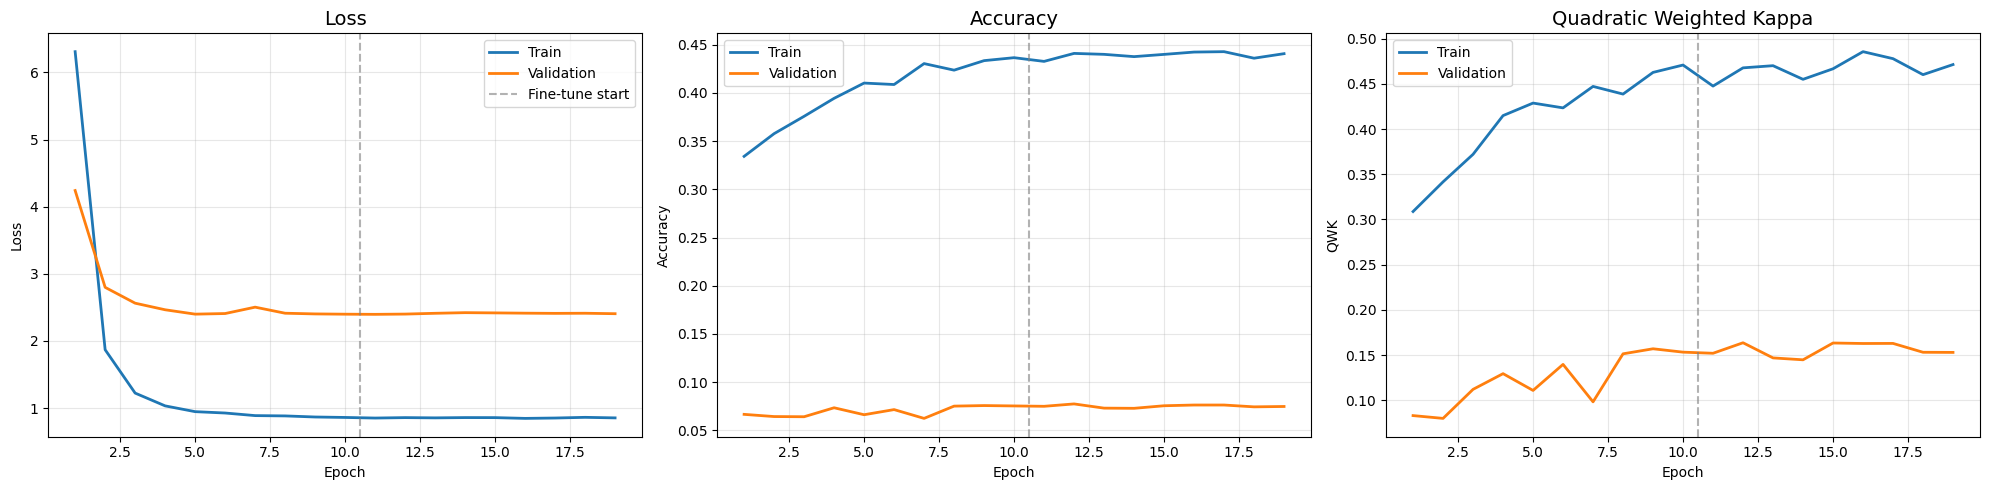

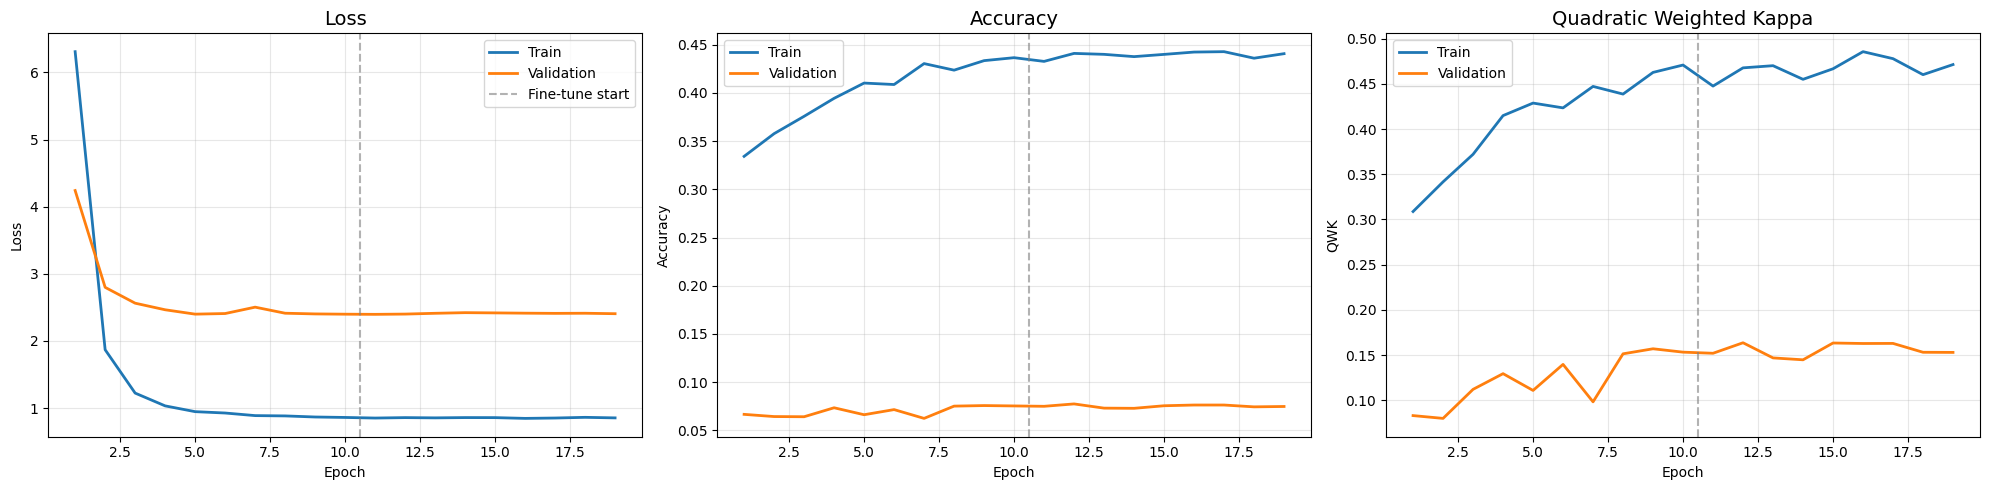

In [10]:
from src.evaluate import plot_training_curves

plot_training_curves(
    history,
    save_path=os.path.join(config.FIGURES_DIR, 'training_curves.png'),
)

## 6. Quick Validation Check

In [ ]:
# Load the best checkpoint and run a quick check
trainer.load_best_checkpoint('phase2')

from src.evaluate import compute_metrics, predict

y_true, y_pred, y_proba = predict(model, loaders['valid'], device)
metrics = compute_metrics(y_true, y_pred, y_proba)

print('\nValidation Results:')
print(f'  QWK      : {metrics["qwk"]:.4f}')
print(f'  Accuracy : {metrics["accuracy"]:.4f}')
print(f'  ROC-AUC  : {metrics["roc_auc_weighted"]:.4f}')

2026-03-26 11:07:10 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase2.pth (epoch 2, QWK=0.1637)
/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages


Validation Results:
  QWK      : 0.1634
  Accuracy : 0.0775
  ROC-AUC  : 0.6732


In [12]:
# Save split CSVs to OUTPUTS_DIR (on Drive) so they persist across Colab sessions
test_df.to_csv(os.path.join(config.OUTPUTS_DIR, 'test_split.csv'), index=False)
valid_df.to_csv(os.path.join(config.OUTPUTS_DIR, 'valid_split.csv'), index=False)
train_df.to_csv(os.path.join(config.OUTPUTS_DIR, 'train_split.csv'), index=False)
print('Split DataFrames saved for reproducible evaluation.')

Split DataFrames saved for reproducible evaluation.


## Export Model to ONNX (Production)

In [ ]:
from src.export import export_to_onnx

onnx_path = export_to_onnx()
print(f"\nONNX model exported to: {onnx_path}")
print("You can now deploy this model with onnxruntime — no PyTorch needed.")

2026-03-26 11:07:25 | src.export | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_phase2.pth (epoch 1, QWK=0.16365554914051494)
2026-03-26 11:07:28 | src.export | INFO | ONNX validation passed (max diff: 1.67e-06)
2026-03-26 11:07:28 | src.export | INFO | ONNX model exported: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx (70.4 MB, opset 17)



ONNX model exported to: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx
You can now deploy this model with onnxruntime — no PyTorch needed.
